In [50]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Image shape: (475, 421)


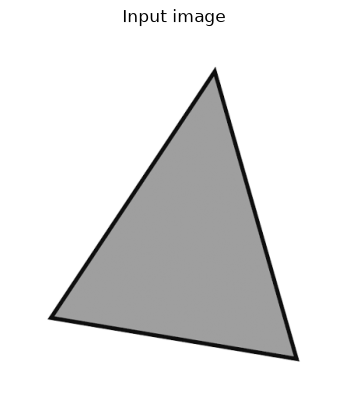

In [ ]:
img = cv2.imread("shape.png", cv2.IMREAD_GRAYSCALE)
print("Image shape:", img.shape)
plt.imshow(img, cmap="gray"); plt.title("Input image"); 
plt.axis("off"); plt.show()

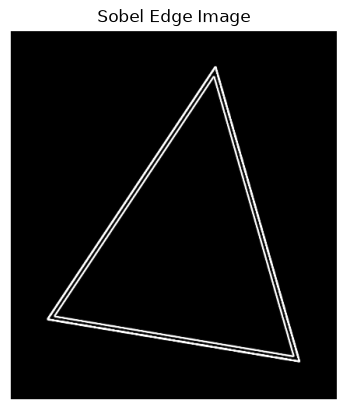

In [52]:
def sobel_filter(image):
    sobel_x = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])

    sobel_y = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ])

    padded = np.pad(image, 1, mode="constant")
    rows, cols = image.shape

    gx = np.zeros((rows, cols), dtype=np.float32)
    gy = np.zeros((rows, cols), dtype=np.float32)

    for i in range(rows):
        for j in range(cols):
            region = padded[i:i+3, j:j+3]

            gx[i, j] = np.sum(region * sobel_x)
            gy[i, j] = np.sum(region * sobel_y)

    magnitude = np.sqrt(gx**2 + gy**2)
    magnitude = np.clip(magnitude, 0, 255)

    return magnitude.astype(np.uint8)


edge_image = sobel_filter(img)

plt.imshow(edge_image, cmap="gray")
plt.title("Sobel Edge Image")
plt.axis("off")
plt.show()

In [53]:
threshold = 100

edge_points = np.argwhere(edge_image > threshold)

print("Number of edge points:", len(edge_points))

Number of edge points: 7530


In [54]:
def hough_euclidean(edge_image, threshold=100, angle_step=1):
    points = np.argwhere(edge_image > threshold)

    rows, cols = edge_image.shape
    diagonal = int(np.ceil(np.sqrt(rows**2 + cols**2)))

    angles = np.arange(-90, 90, angle_step)
    distances = np.arange(-diagonal, diagonal + 1)

    accumulator = np.zeros(
        (len(distances), len(angles)),
        dtype=np.uint32
    )

    for y, x in points:
        for angle_index, angle in enumerate(angles):
            theta = np.deg2rad(angle)
            r = round(x * np.cos(theta) + y * np.sin(theta))
            distance_index = r + diagonal
            accumulator[distance_index, angle_index] += 1

    return accumulator, distances, angles


accumulator_e, distances_e, angles_e = hough_euclidean(
    edge_image,
    threshold=100
)

print("Accumulator shape:", accumulator_e.shape)

Accumulator shape: (1271, 180)


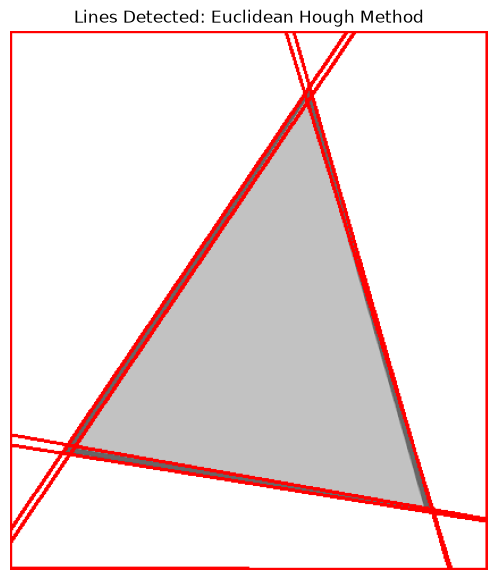

In [55]:
def draw_hough_lines(image, accumulator, distances, angles,
                     num_lines=10, min_votes=80):
    output = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
    acc = accumulator.copy()

    for _ in range(num_lines):
        index = np.unravel_index(np.argmax(acc), acc.shape)
        votes = acc[index]

        if votes < min_votes:
            break

        distance_index, angle_index = index
        r = distances[distance_index]
        theta = np.deg2rad(angles[angle_index])

        a = np.cos(theta)
        b = np.sin(theta)

        x0 = a * r
        y0 = b * r

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)

        cv2.line(output, (x1, y1), (x2, y2), (0, 0, 255), 2)

        # Suppress this peak and nearby values to avoid duplicate lines.
        r_start = max(0, distance_index - 5)
        r_end = min(acc.shape[0], distance_index + 6)
        theta_start = max(0, angle_index - 5)
        theta_end = min(acc.shape[1], angle_index + 6)
        acc[r_start:r_end, theta_start:theta_end] = 0

    return output


result_e = draw_hough_lines(
    img,
    accumulator_e,
    distances_e,
    angles_e,
    num_lines=10,
    min_votes=80
)

plt.figure(figsize=(9, 7))
plt.imshow(cv2.cvtColor(result_e, cv2.COLOR_BGR2RGB))
plt.title("Lines Detected: Euclidean Hough Method")
plt.axis("off")
plt.show()

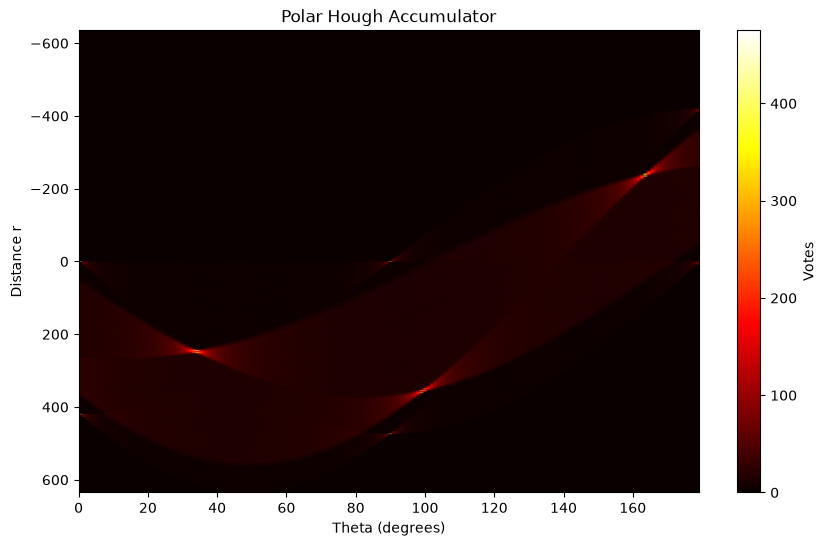

In [ ]:
def hough_polar(edge_image, threshold=100, angle_step=1):
    rows, cols = edge_image.shape
    points = np.argwhere(edge_image > threshold)

    max_r = int(np.ceil(np.sqrt(rows**2 + cols**2)))
    angles = np.deg2rad(np.arange(0, 180, angle_step))
    r_values = np.arange(-max_r, max_r + 1)

    accumulator = np.zeros(
        (len(r_values), len(angles)),
        dtype=np.uint32)

    cos_values = np.cos(angles)
    sin_values = np.sin(angles)

    for y, x in points:
        r = x * cos_values + y * sin_values
        r_indices = np.rint(r).astype(int) + max_r

        for angle_index, r_index in enumerate(r_indices):
            accumulator[r_index, angle_index] += 1
            
    return accumulator, r_values, np.rad2deg(angles)


accumulator_p, r_values_p, angles_p = hough_polar(
    edge_image,
    threshold=100)

plt.figure(figsize=(10, 6))
plt.imshow(accumulator_p, cmap="hot", aspect="auto",
    extent=[
        angles_p[0],
        angles_p[-1],
        r_values_p[-1],
        r_values_p[0]])
plt.xlabel("Theta (degrees)")
plt.ylabel("Distance r")
plt.title("Polar Hough Accumulator")
plt.colorbar(label="Votes")
plt.show()

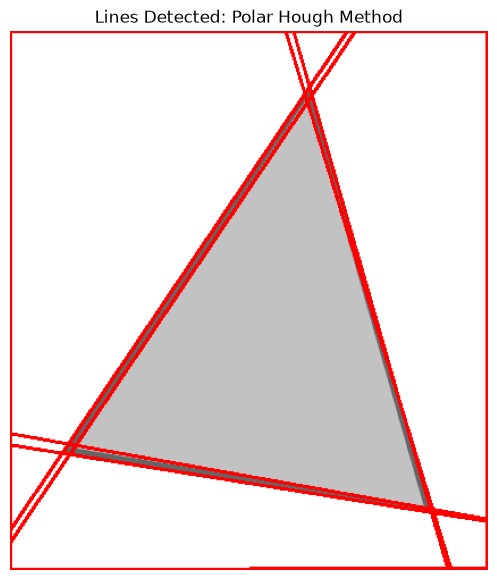

In [57]:
result_p = draw_hough_lines(img,accumulator_p, r_values_p,angles_p, 
                            num_lines=10, min_votes=80)

plt.figure(figsize=(9, 7))
plt.imshow(cv2.cvtColor(result_p, cv2.COLOR_BGR2RGB))
plt.title("Lines Detected: Polar Hough Method")
plt.axis("off")
plt.show()